# Decision Trees Explained With a Simple Buy, Hold or Sell Model
This notebook builds a tiny decision tree on a simulated price series that labels each day buy, hold or sell from the next day's move. You will watch it pick splits by Gini impurity, read the finished tree as if/then rules, and see what happens to test accuracy when you let the tree grow too deep.

*Toy data, toy model. This is not a trading strategy and nothing here is financial advice.*

## Setup
Only numpy, pandas and matplotlib. The post mentions scikit-learn's `DecisionTreeClassifier` and `export_text`. To keep this notebook free of extra installs, I write a tiny tree in numpy that does the same job: Gini impurity, greedy splits, maximum depth and minimum days per leaf. I also write a small rule printer that copies the `export_text` style.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

LABELS = ["sell", "hold", "buy"]
COLORS = {"sell": "#d62728", "hold": "#7f7f7f", "buy": "#2ca02c"}
FEATURES = ["return_pct", "volume_ratio"]

## Step 1: Simulate a price series
**This data is simulated.** I generate about 400 trading days of volume and daily returns. I also plant two patterns so the tree has something real to find:
* after a drop worse than minus 2 percent, the next day tends to fall too
* after an unusually busy day (volume ratio above 1.5), the next day tends to rise

Everything else is random noise. Compare the rules the tree finds at the end with these two planted patterns.

In [2]:
rng = np.random.default_rng(42)
n_days = 420

volume = 1_000_000 * rng.lognormal(0, 0.4, n_days)
volume[rng.random(n_days) < 0.08] *= 1.8          # occasional busy days
past_avg = pd.Series(volume).rolling(20).mean().shift(1).to_numpy()
true_vol_ratio = volume / past_avg

returns = np.zeros(n_days)
returns[0] = rng.normal(0, 1.3)
for t in range(n_days - 1):
    nudge = 0.0
    if returns[t] < -2:
        nudge = -1.5                              # planted: drops follow drops
    elif true_vol_ratio[t] > 1.5:
        nudge = 1.5                               # planted: busy days lead to rises
    returns[t + 1] = nudge + rng.normal(0, 1.3)

prices = 100 * np.cumprod(1 + returns / 100)
print(f"Simulated {n_days} days, price went from {prices[0]:.2f} to {prices[-1]:.2f}")

Simulated 420 days, price went from 99.85 to 123.34


## Step 2: Features from today, label from tomorrow
Now I rebuild everything from the price and volume columns, the same way you would from a spreadsheet.
* **return_pct**: today's close compared with yesterday's, in percent.
* **volume_ratio**: today's volume divided by the average of the previous 20 days.
* **label**: buy if *tomorrow* rose more than 1 percent, sell if it fell more than 1 percent, otherwise hold.

The features only use what you know at today's close. Only the label gets to look at tomorrow. If tomorrow leaks into a feature, you have leakage.

In [3]:
df = pd.DataFrame({"close": prices, "volume": volume})
df["return_pct"] = df["close"].pct_change() * 100
df["volume_ratio"] = df["volume"] / df["volume"].rolling(20).mean().shift(1)
df["next_return_pct"] = df["return_pct"].shift(-1)   # tomorrow: label only!
df = df.dropna().reset_index(drop=True)
df["label"] = np.select([df["next_return_pct"] > 1, df["next_return_pct"] < -1],
                        ["buy", "sell"], "hold")

print(df[["close", "return_pct", "volume_ratio", "next_return_pct", "label"]].head(6).round(2))
print("\nLabel counts:", df["label"].value_counts().to_dict())

    close  return_pct  volume_ratio  next_return_pct label
0  108.90        1.11          0.83            -0.92  hold
1  107.90       -0.92          0.68             1.26   buy
2  109.26        1.26          1.46            -0.47  hold
3  108.75       -0.47          0.83            -0.64  hold
4  108.05       -0.64          0.76             1.18   buy
5  109.33        1.18          0.77             0.04  hold

Label counts: {'hold': 199, 'buy': 107, 'sell': 93}


## Step 3: Split into earlier and later days
The tree learns from the first 70 percent of days and gets tested on the last 30 percent. I split by time and do not shuffle, because in real life you only ever predict the future.

In [4]:
X = df[FEATURES].to_numpy()
y = df["label"].map({lab: i for i, lab in enumerate(LABELS)}).to_numpy()

cut = int(len(df) * 0.7)
X_train, y_train = X[:cut], y[:cut]
X_test, y_test = X[cut:], y[cut:]
print(f"Training days: {len(y_train)}, test days: {len(y_test)}")

Training days: 279, test days: 120


## Step 4: Gini impurity, checked against the post
Gini impurity is the chance of guessing a day's label wrong if you guess at random using the group's own proportions. Take each label's share, square it, add the squares up, and subtract the total from 1.

First a sanity check with the 10-day example from the post (3 sell, 4 hold, 3 buy) and the two candidate splits A and B.

In [5]:
def gini(counts):
    counts = np.asarray(counts, dtype=float)
    p = counts / counts.sum()
    return 1 - (p ** 2).sum()

def weighted_gini(left, right):
    nl, nr = sum(left), sum(right)
    return (nl * gini(left) + nr * gini(right)) / (nl + nr)

# counts are in the order [sell, hold, buy]
print(f"Starting mess, 10 days:      {gini([3, 4, 3]):.2f}")
print(f"Candidate A (return < -2%):  {weighted_gini([3, 1, 0], [0, 3, 3]):.2f}")
print(f"Candidate B (volume > 1.5):  {weighted_gini([2, 1, 2], [1, 3, 1]):.2f}")
print(f"Our simulated training days: {gini(np.bincount(y_train, minlength=3)):.3f}")

Starting mess, 10 days:      0.66
Candidate A (return < -2%):  0.45
Candidate B (volume > 1.5):  0.60
Our simulated training days: 0.612


## Step 5: A tiny decision tree in numpy
Here is the whole algorithm. For each feature, the tree sorts the days and tries a cut between every pair of neighbouring values. It scores each cut by weighted Gini impurity and keeps the lowest. Then it repeats the same greedy step inside each side, until it hits the maximum depth, a pure group, or a leaf that would be smaller than `min_leaf`. A day that answers "yes" to `feature <= threshold` goes left.

In [6]:
def best_split(X, y, min_leaf):
    n = len(y)
    best_f, best_thr, best_score = None, None, gini(np.bincount(y, minlength=3))
    for f in range(X.shape[1]):
        order = np.argsort(X[:, f])
        xs, onehot = X[order, f], np.eye(3)[y[order]]
        left = np.cumsum(onehot, axis=0)[:-1]          # counts left of each cut
        right = onehot.sum(axis=0) - left
        nl = np.arange(1, n)[:, None]
        nr = n - nl
        g_left = 1 - ((left / nl) ** 2).sum(axis=1)
        g_right = 1 - ((right / nr) ** 2).sum(axis=1)
        score = (nl[:, 0] * g_left + nr[:, 0] * g_right) / n
        valid = (xs[1:] > xs[:-1]) & (nl[:, 0] >= min_leaf) & (nr[:, 0] >= min_leaf)
        if valid.any():
            i = np.argmin(np.where(valid, score, np.inf))
            if score[i] < best_score - 1e-12:
                best_f, best_thr, best_score = f, (xs[i] + xs[i + 1]) / 2, score[i]
    return best_f, best_thr

def build_tree(X, y, max_depth, min_leaf=1, depth=0):
    counts = np.bincount(y, minlength=3)
    node = {"counts": counts, "label": int(np.argmax(counts))}
    if depth < max_depth and gini(counts) > 0:
        f, thr = best_split(X, y, min_leaf)
        if f is not None:
            go_left = X[:, f] <= thr
            node.update(feature=f, threshold=thr,
                        left=build_tree(X[go_left], y[go_left], max_depth, min_leaf, depth + 1),
                        right=build_tree(X[~go_left], y[~go_left], max_depth, min_leaf, depth + 1))
    return node

def predict(node, X):
    out = []
    for row in X:
        n = node
        while "feature" in n:
            n = n["left"] if row[n["feature"]] <= n["threshold"] else n["right"]
        out.append(n["label"])
    return np.array(out)

## Step 6: Train a depth 2 tree and read it as rules
Same stopping rules as the post: at most 2 questions in a row, and each leaf needs at least 5 training days so no rule rests on one lucky afternoon. Then I print the tree the way `export_text` would, with the counts that back each leaf. Read each leaf and ask three questions: does it make sense, how many days support it, and does it hold up on the later days?

In [7]:
def tree_rules(node, indent=""):
    if "feature" not in node:
        c, lab = node["counts"], node["label"]
        return [f"{indent}|--- {LABELS[lab]}  ({c[lab]} of {c.sum()} days)"]
    name, thr = FEATURES[node["feature"]], node["threshold"]
    return ([f"{indent}|--- {name} <= {thr:.2f}"] + tree_rules(node["left"], indent + "|   ") +
            [f"{indent}|--- {name} >  {thr:.2f}"] + tree_rules(node["right"], indent + "|   "))

tree2 = build_tree(X_train, y_train, max_depth=2, min_leaf=5)
print("\n".join(tree_rules(tree2)))

acc_train = (predict(tree2, X_train) == y_train).mean()
acc_test = (predict(tree2, X_test) == y_test).mean()
baseline = (y_test == LABELS.index("hold")).mean()
print(f"\nDepth 2 accuracy  train: {acc_train:.1%}  test: {acc_test:.1%}")
print(f"'Always hold' baseline on test days: {baseline:.1%}")

|--- volume_ratio <= 1.67
|   |--- return_pct <= -2.02
|   |   |--- sell  (13 of 13 days)
|   |--- return_pct >  -2.02
|   |   |--- hold  (142 of 236 days)
|--- volume_ratio >  1.67
|   |--- return_pct <= -1.35
|   |   |--- buy  (3 of 5 days)
|   |--- return_pct >  -1.35
|   |   |--- buy  (22 of 25 days)

Depth 2 accuracy  train: 64.5%  test: 55.0%
'Always hold' baseline on test days: 45.0%


## Chart 1: Where the tree draws its lines
Each dot is a training day, coloured by what actually happened the next day. The shaded background shows what the depth 2 tree would answer at each point. Every split is a straight cut along one feature, so the regions are always rectangles.

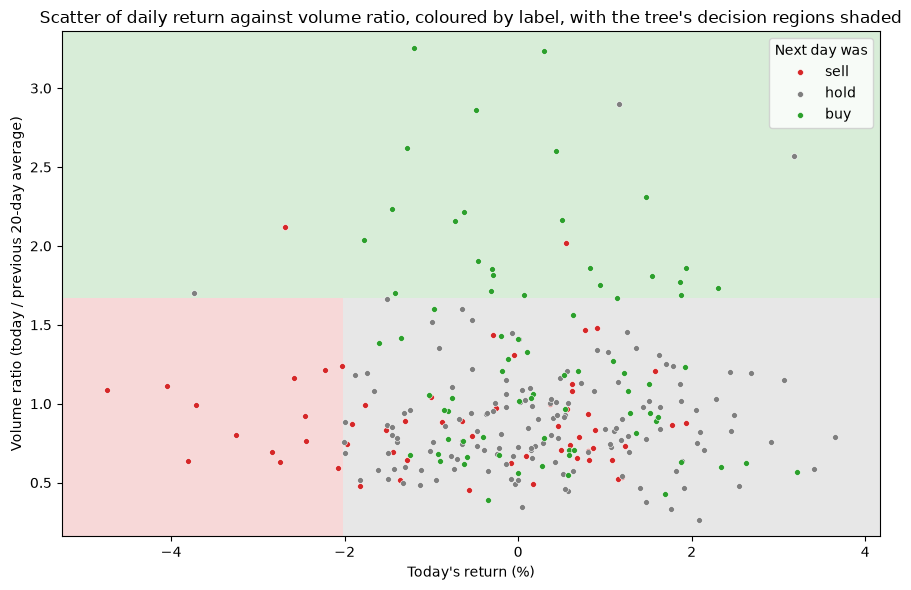

In [8]:
gx = np.linspace(X_train[:, 0].min() - 0.5, X_train[:, 0].max() + 0.5, 250)
gy = np.linspace(X_train[:, 1].min() - 0.1, X_train[:, 1].max() + 0.1, 250)
xx, yy = np.meshgrid(gx, gy)
zz = predict(tree2, np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

plt.figure(figsize=(9, 6))
plt.pcolormesh(xx, yy, zz, cmap=ListedColormap([COLORS[l] for l in LABELS]),
               vmin=-0.5, vmax=2.5, alpha=0.18, shading="auto")
for i, lab in enumerate(LABELS):
    m = y_train == i
    plt.scatter(X_train[m, 0], X_train[m, 1], s=18, color=COLORS[lab], label=lab,
                edgecolor="white", linewidth=0.4)
plt.xlabel("Today's return (%)")
plt.ylabel("Volume ratio (today / previous 20-day average)")
plt.legend(title="Next day was")
plt.title("Scatter of daily return against volume ratio, coloured by label, with the tree's decision regions shaded")
plt.tight_layout()
plt.show()

## Chart 2: The tree as a diagram
Here is the same depth 2 tree drawn as boxes. Each box shows the question it asks, how many training days reached it, the label counts, and the answer it would give. "Yes" goes left and "no" goes right. The counts are the honest confidence of each rule.

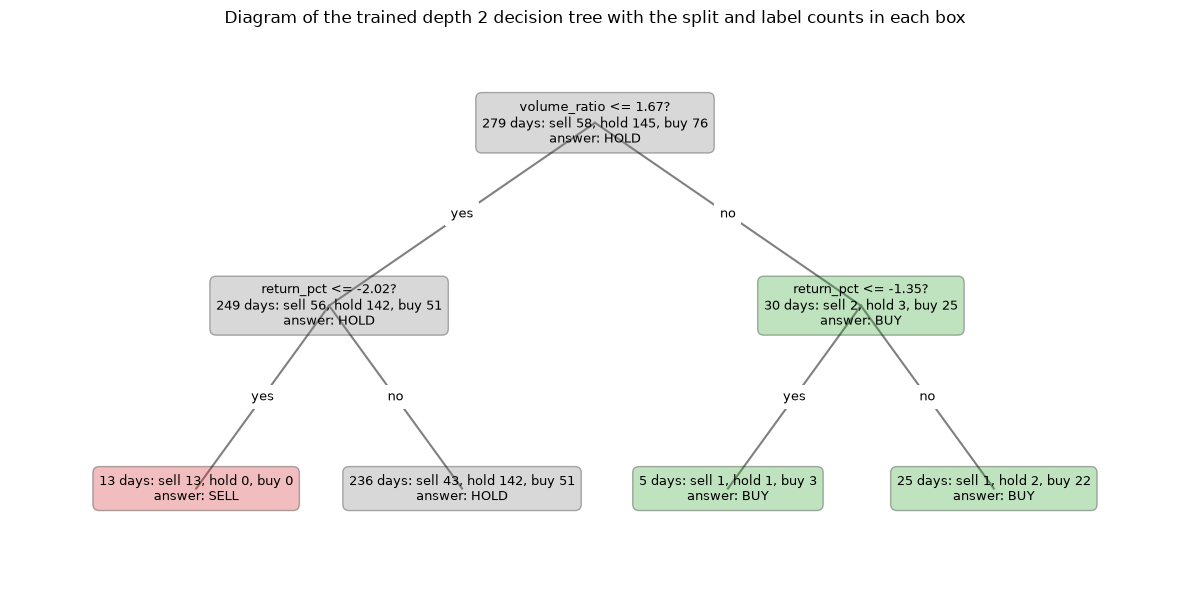

In [9]:
xpos, nodes, next_leaf = {}, [], [0]

def layout(node, depth):
    if "feature" in node:
        x = (layout(node["left"], depth + 1) + layout(node["right"], depth + 1)) / 2
    else:
        x = next_leaf[0]
        next_leaf[0] += 1
    xpos[id(node)] = x
    nodes.append((node, depth))
    return x

layout(tree2, 0)
max_d = max(d for _, d in nodes)

plt.figure(figsize=(12, 6))
ax = plt.gca()
for node, d in nodes:
    x, yv = xpos[id(node)], -d
    c, lab = node["counts"], LABELS[node["label"]]
    text = f"{c.sum()} days: sell {c[0]}, hold {c[1]}, buy {c[2]}\nanswer: {lab.upper()}"
    if "feature" in node:
        text = f"{FEATURES[node['feature']]} <= {node['threshold']:.2f}?\n" + text
        for child, tag in ((node["left"], "yes"), (node["right"], "no")):
            cx = xpos[id(child)]
            ax.plot([x, cx], [yv, yv - 1], color="grey", zorder=1)
            ax.text((x + cx) / 2, yv - 0.5, tag, ha="center", va="center", fontsize=9,
                    bbox=dict(fc="white", ec="none"), zorder=2)
    ax.text(x, yv, text, ha="center", va="center", fontsize=9, zorder=3,
            bbox=dict(boxstyle="round,pad=0.5", fc=COLORS[lab], alpha=0.3, ec="black"))
ax.set_xlim(-0.7, next_leaf[0] - 0.3)
ax.set_ylim(-max_d - 0.5, 0.5)
ax.axis("off")
plt.title("Diagram of the trained depth 2 decision tree with the split and label counts in each box")
plt.tight_layout()
plt.show()

## Step 7: Let the tree grow and watch it overfit
Now I change one setting: maximum depth, from 1 to 10. I also drop the leaf size limit to 1 day so the tree is free to memorise. Training accuracy keeps climbing, because the tree learns the quirks of the days it saw. Test accuracy on the later days tells the honest story. The dashed line is the dumb "always hold" baseline, and any tree has to beat it.

In [10]:
depths = list(range(1, 11))
train_acc, test_acc = [], []
for d in depths:
    t = build_tree(X_train, y_train, max_depth=d, min_leaf=1)
    train_acc.append((predict(t, X_train) == y_train).mean())
    test_acc.append((predict(t, X_test) == y_test).mean())

print("depth  train   test")
for d, a, b in zip(depths, train_acc, test_acc):
    print(f"{d:>5}  {a:.1%}  {b:.1%}")
print(f"Best test depth: {depths[int(np.argmax(test_acc))]}, always-hold baseline: {baseline:.1%}")

depth  train   test
    1  59.9%  46.7%
    2  64.9%  56.7%
    3  65.6%  55.0%
    4  65.6%  55.0%
    5  68.1%  56.7%
    6  69.5%  55.8%
    7  71.3%  55.8%
    8  73.8%  55.0%
    9  79.6%  52.5%
   10  84.2%  50.8%
Best test depth: 2, always-hold baseline: 45.0%


## Chart 3: Training days versus later test days

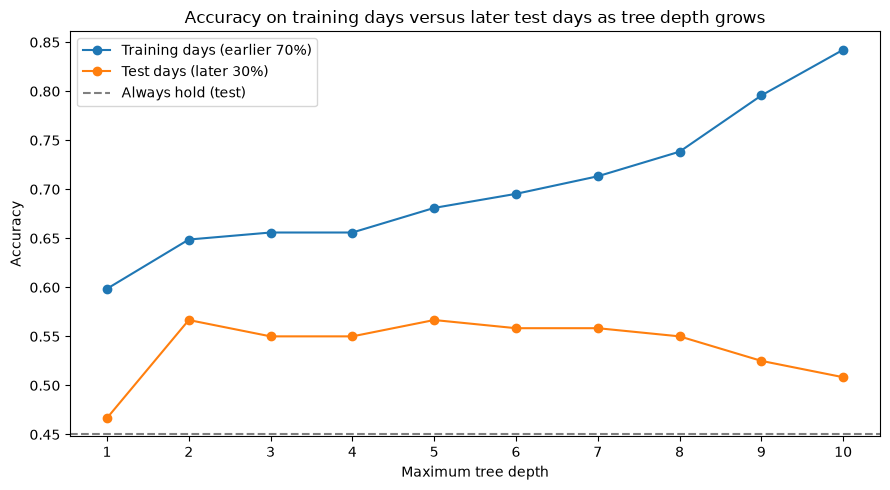

In [11]:
plt.figure(figsize=(9, 5))
plt.plot(depths, train_acc, marker="o", label="Training days (earlier 70%)")
plt.plot(depths, test_acc, marker="o", label="Test days (later 30%)")
plt.axhline(baseline, color="grey", linestyle="--", label="Always hold (test)")
plt.xlabel("Maximum tree depth")
plt.ylabel("Accuracy")
plt.xticks(depths)
plt.legend()
plt.title("Accuracy on training days versus later test days as tree depth grows")
plt.tight_layout()
plt.show()

## What to take away
The shallow tree fits on an index card, and you can check every line of it. Compare its rules with the two patterns I planted in Step 1. The deep tree scores better on the days it trained on and usually worse on the days it never saw, and that is overfitting. Try it yourself: change the seed in `default_rng(42)`, change `min_leaf`, or remove one feature. Then see which rules survive. A rule that only shows up under one seed was luck.